# Milestone 4 — Which Images Compress Well?

Test rank and compression across artificial image patterns and rotations.

In [1]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("No personal photo yet: add data/my_photo.png before final submission.")

## Build five test patterns

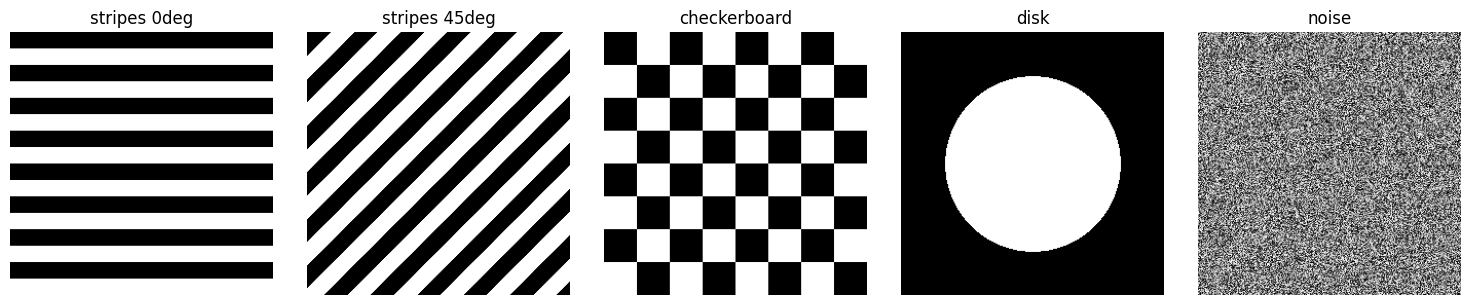

In [2]:
N=256
i,j=np.meshgrid(np.arange(N),np.arange(N),indexing="ij")
def stripes(angle,width=16):
 t=np.deg2rad(angle)
 return 255.0*(np.floor((i*np.cos(t)+j*np.sin(t))/width)%2)
rng=np.random.default_rng(0)
patterns={"stripes 0deg":stripes(0),"stripes 45deg":stripes(45),"checkerboard":255.0*((i//32+j//32)%2),"disk":255.0*((i-N/2)**2+(j-N/2)**2<(N/3)**2),"noise":rng.integers(0,256,size=(N,N)).astype(float)}
fig,axs=plt.subplots(1,5,figsize=(15,3))
for ax,(name,M) in zip(axs,patterns.items()):ax.imshow(M,cmap="gray");ax.set_title(name);ax.axis("off")
plt.tight_layout();plt.show()

Prediction to record before running: axis-aligned stripes and checkerboard should be low rank; random noise should be hardest.

## Numerical comparison

In [3]:
for name,M in patterns.items():
    ss=np.linalg.svd(M,compute_uv=False);k5=k_for_error(ss,0.05)
    print(f"{name:18s} rank={np.linalg.matrix_rank(M):3d} k5={k5:3d} ratio={compression_ratio(N,N,k5):.2f}")
print("Tilted image top-left corner:\n", stripes(45)[:4,:12]/255)


stripes 0deg       rank=  1 k5=  1 ratio=127.75
stripes 45deg      rank=182 k5= 64 ratio=2.00
checkerboard       rank=  2 k5=  2 ratio=63.88
disk               rank= 51 k5= 26 ratio=4.91
noise              rank=256 k5=198 ratio=0.65
Tilted image top-left corner:
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


A tilted image has shifted row patterns; many rows are not scalar multiples of one another.

## Angles figure

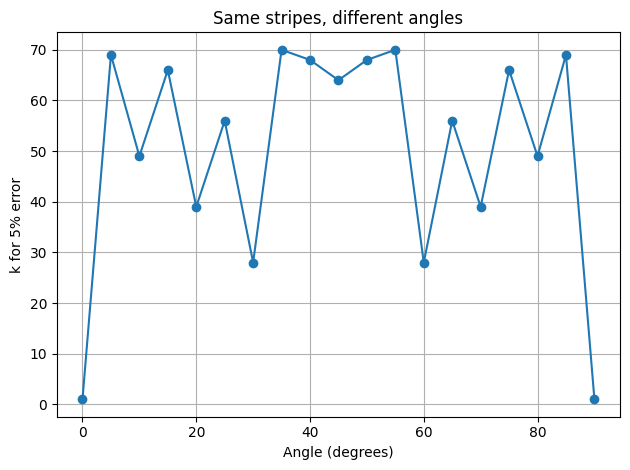

k at 0° and 5°: 1 69


In [4]:
angles=np.arange(0,91,5)
needed=[k_for_error(np.linalg.svd(stripes(float(a)),compute_uv=False),0.05) for a in angles]
plt.plot(angles,needed,"o-");plt.xlabel("Angle (degrees)");plt.ylabel("k for 5% error")
plt.title("Same stripes, different angles");plt.grid(True);plt.tight_layout()
plt.savefig(project_root/"figures"/"angles.png",dpi=150);plt.show()
print("k at 0° and 5°:",needed[0],needed[1])

Tilting the stripes raises the rank needed to achieve the same approximation error.

## Color extension

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RGB relative error at rank 50/channel 0.07872080850029223


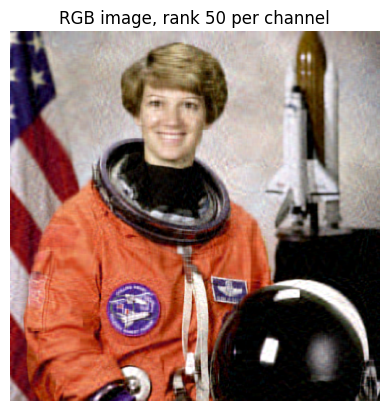

In [5]:
C=data.astronaut().astype(float)
C50=np.stack([rank_k_approx(C[:,:,c],50) for c in range(3)],axis=2)
print("RGB relative error at rank 50/channel",rel_error(C,C50))
plt.imshow(np.clip(C50,0,255).astype(np.uint8));plt.title("RGB image, rank 50 per channel");plt.axis("off");plt.show()

Storage for three separate color channels is three times the grayscale factor storage at the same k.

## What we found

**To complete after running:** Record the exact output values from the cells above, explain what they mean in your own words, and check your findings against the assignment instructions.